In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.naive_bayes import MultinomialNB
from sklearn.naive_bayes import BernoulliNB

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report
)

In [2]:
train_data = fetch_20newsgroups(
    subset="train",
    remove=("headers", "footers", "quotes")
)

print("Number of training documents:", len(train_data.data))
print("Number of categories:", len(train_data.target_names))

Number of training documents: 11314
Number of categories: 20


In [3]:
print(train_data.target_names)

['alt.atheism', 'comp.graphics', 'comp.os.ms-windows.misc', 'comp.sys.ibm.pc.hardware', 'comp.sys.mac.hardware', 'comp.windows.x', 'misc.forsale', 'rec.autos', 'rec.motorcycles', 'rec.sport.baseball', 'rec.sport.hockey', 'sci.crypt', 'sci.electronics', 'sci.med', 'sci.space', 'soc.religion.christian', 'talk.politics.guns', 'talk.politics.mideast', 'talk.politics.misc', 'talk.religion.misc']


In [4]:
test_data = fetch_20newsgroups(
    subset="test",
    remove=("headers", "footers", "quotes")
)

print("Number of testing documents:", len(test_data.data))

Number of testing documents: 7532


In [5]:
X_train_text = train_data.data
y_train = train_data.target

X_test_text = test_data.data
y_test = test_data.target

In [6]:
print("First document:")
print(X_train_text[0])

print("\nFirst document's class:")
print(train_data.target_names[y_train[0]])

First document:
I was wondering if anyone out there could enlighten me on this car I saw
the other day. It was a 2-door sports car, looked to be from the late 60s/
early 70s. It was called a Bricklin. The doors were really small. In addition,
the front bumper was separate from the rest of the body. This is 
all I know. If anyone can tellme a model name, engine specs, years
of production, where this car is made, history, or whatever info you
have on this funky looking car, please e-mail.

First document's class:
rec.autos


In [8]:
vectorizer = TfidfVectorizer(
    stop_words="english",
    max_features=50000
)

In [10]:
X_train = vectorizer.fit_transform(X_train_text)

In [12]:
X_test = vectorizer.transform(X_test_text)

In [13]:
print("Training matrix shape:", X_train.shape)
print("Testing matrix shape:", X_test.shape)

Training matrix shape: (11314, 50000)
Testing matrix shape: (7532, 50000)


In [15]:
multinomial_nb = MultinomialNB()
multinomial_nb.fit(
    X_train,
    y_train
)

MultinomialNB()

In [18]:
y_pred_multinomial = multinomial_nb.predict(
    X_test
)

In [21]:
accuracy_multinomial = accuracy_score(
    y_test,
    y_pred_multinomial
)

In [22]:
f1_multinomial = f1_score(
    y_test,
    y_pred_multinomial,
    average="weighted"
)

In [23]:
print("Multinomial Naïve Bayes")
print("-----------------------")
print("Accuracy :", accuracy_multinomial)
print("F1-score :", f1_multinomial)

Multinomial Naïve Bayes
-----------------------
Accuracy : 0.6797663303239512
F1-score : 0.6664892286445232


In [24]:
print(
    classification_report(
        y_test,
        y_pred_multinomial,
        target_names=test_data.target_names
    )
)

                          precision    recall  f1-score   support

             alt.atheism       0.76      0.20      0.31       319
           comp.graphics       0.66      0.69      0.67       389
 comp.os.ms-windows.misc       0.66      0.60      0.63       394
comp.sys.ibm.pc.hardware       0.61      0.74      0.67       392
   comp.sys.mac.hardware       0.77      0.67      0.72       385
          comp.windows.x       0.81      0.76      0.79       395
            misc.forsale       0.78      0.77      0.78       390
               rec.autos       0.81      0.73      0.77       396
         rec.motorcycles       0.85      0.74      0.79       398
      rec.sport.baseball       0.91      0.80      0.85       397
        rec.sport.hockey       0.57      0.93      0.71       399
               sci.crypt       0.61      0.79      0.69       396
         sci.electronics       0.71      0.52      0.60       393
                 sci.med       0.88      0.76      0.82       396
         

In [25]:
bernoulli_vectorizer = TfidfVectorizer(
    stop_words="english",
    max_features=50000,
    binary=True,
    use_idf=False,
    norm=None
)

In [26]:
X_train_bernoulli = bernoulli_vectorizer.fit_transform(
    X_train_text
)

In [27]:
X_test_bernoulli = bernoulli_vectorizer.transform(
    X_test_text
)

In [28]:
print(
    "Training matrix:",
    X_train_bernoulli.shape
)

print(
    "Testing matrix:",
    X_test_bernoulli.shape
)

Training matrix: (11314, 50000)
Testing matrix: (7532, 50000)


In [29]:
bernoulli_nb = BernoulliNB()

In [30]:
bernoulli_nb.fit(
    X_train_bernoulli,
    y_train
)

BernoulliNB()

In [31]:
y_pred_bernoulli = bernoulli_nb.predict(
    X_test_bernoulli
)

In [33]:
accuracy_bernoulli = accuracy_score(
    y_test,
    y_pred_bernoulli
)

In [34]:
f1_bernoulli = f1_score(
    y_test,
    y_pred_bernoulli,
    average="weighted"
)

In [35]:
print("Bernoulli Naïve Bayes")
print("--------------------")
print("Accuracy :", accuracy_bernoulli)
print("F1-score :", f1_bernoulli)

Bernoulli Naïve Bayes
--------------------
Accuracy : 0.4794211364843335
F1-score : 0.47300492235620695


In [36]:
print(
    classification_report(
        y_test,
        y_pred_bernoulli,
        target_names=test_data.target_names
    )
)

                          precision    recall  f1-score   support

             alt.atheism       0.73      0.13      0.22       319
           comp.graphics       0.56      0.50      0.53       389
 comp.os.ms-windows.misc       0.33      0.00      0.01       394
comp.sys.ibm.pc.hardware       0.45      0.71      0.55       392
   comp.sys.mac.hardware       0.36      0.79      0.49       385
          comp.windows.x       0.83      0.39      0.53       395
            misc.forsale       0.88      0.66      0.75       390
               rec.autos       0.41      0.70      0.52       396
         rec.motorcycles       0.18      0.93      0.31       398
      rec.sport.baseball       0.71      0.78      0.74       397
        rec.sport.hockey       0.99      0.53      0.69       399
               sci.crypt       0.78      0.38      0.51       396
         sci.electronics       0.55      0.53      0.54       393
                 sci.med       0.90      0.36      0.52       396
         

In [37]:
results = pd.DataFrame({
    "Model": [
        "Multinomial Naïve Bayes",
        "Bernoulli Naïve Bayes"
    ],
    "Accuracy": [
        accuracy_multinomial,
        accuracy_bernoulli
    ],
    "F1-score": [
        f1_multinomial,
        f1_bernoulli
    ]
})

print(results)

                     Model  Accuracy  F1-score
0  Multinomial Naïve Bayes  0.679766  0.666489
1    Bernoulli Naïve Bayes  0.479421  0.473005


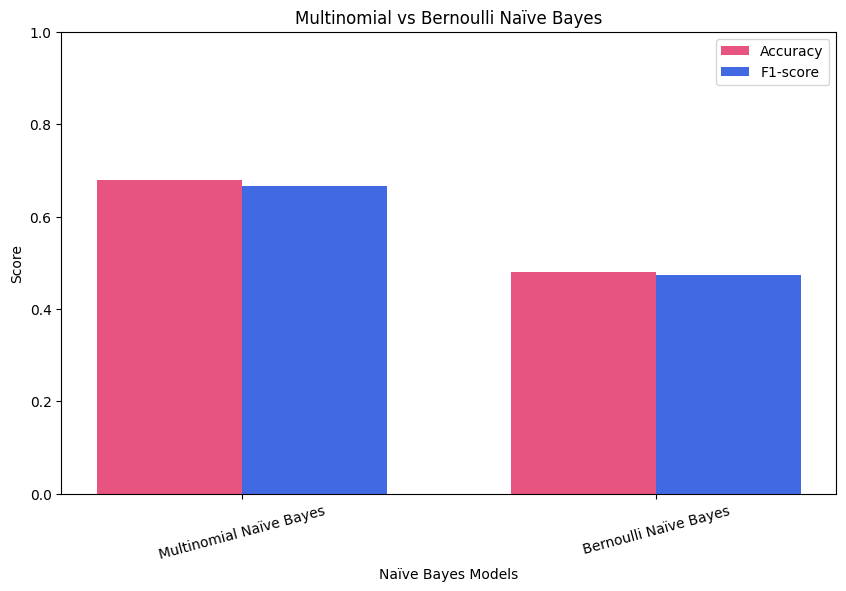

In [38]:
x = np.arange(len(results["Model"]))
width = 0.35

plt.figure(figsize=(10, 6))

plt.bar(
    x - width/2,
    results["Accuracy"],
    width,
    label="Accuracy",
    color="#E75480"
)

plt.bar(
    x + width/2,
    results["F1-score"],
    width,
    label="F1-score",
    color="#4169E1"
)

plt.xticks(
    x,
    results["Model"],
    rotation=15
)

plt.ylabel("Score")
plt.xlabel("Naïve Bayes Models")
plt.title(
    "Multinomial vs Bernoulli Naïve Bayes"
)

plt.ylim(0, 1)
plt.legend()

plt.show()

In [39]:
if accuracy_multinomial > accuracy_bernoulli:
    print("Multinomial Naïve Bayes has higher accuracy.")
elif accuracy_bernoulli > accuracy_multinomial:
    print("Bernoulli Naïve Bayes has higher accuracy.")
else:
    print("Both models have the same accuracy.")

Multinomial Naïve Bayes has higher accuracy.


In [40]:
if f1_multinomial > f1_bernoulli:
    print("Multinomial Naïve Bayes has higher F1-score.")
elif f1_bernoulli > f1_multinomial:
    print("Bernoulli Naïve Bayes has higher F1-score.")
else:
    print("Both models have the same F1-score.")

Multinomial Naïve Bayes has higher F1-score.
